# NCAA Basketball Tournament Prediction 🏀 

Este projeto tem como objetivo prever o resultado dos jogos do torneio de basquete da NCAA utilizando técnicas de Machine Learning.

A proposta segue a competição do Kaggle "March Machine Learning Mania 2025".

Autores:
- Aira Winner Sousa Ramos Torres
- Emanuel Victor Fonseca de Araujo

Criação: 04/2026
<br><br>
___


## Introdução

O Basquete da NCAA é uma competição entre times universitários americanos estruturada em duas grandes fases:<br>
1. **Temporada Regular** - Fase de qualificação onde os times participam de vários jogos dentro de sua liga regional.
    - Acontece ao longo de vários meses, centenas de times jogam muitos jogos entre si
    - Essa fase serve para construir o histórico de desempenho das equipes: vitórias, derrotas, força dos adversários, estatísticas, etc.
    - No fim dessa fase, os times são avaliados com base no desempenho acumulado.
2. **Torneio** - Fase de mata-mata em um chaveamento com os times mais bem pontuados da temporada regular.

O objetivo é prever o resultado dos confrontos do **Torneio de 2025**, estimando a **probabilidade de vitória de um time contra outro**.

A saída do modelo é um valor de probabilidade entre 0 e 1, tal que quanto menor o erro em relação ao resultado real do jogo, melhor o modelo.

### Abordagens utilizadas

Para alcançar tal objetivo, serão adotadas três estratégias sequenciais:

- **Primeira abordagem**: um modelo de **Regressão Logística**, amplamente utilizado em problemas de classificação binária e se destaca por sua interpretabilidade e boa calibração de probabilidades.

- **Segunda abordagem**: um modelo baseado em *Gradient Boosting*, especificamente o **LightGBM**, capaz de capturar relações não lineares e interações complexas entre as variáveis. 
    - Diferentemente da regressão logística, o LightGBM consegue explorar padrões mais sofisticados nas estatísticas das equipes, como combinações entre desempenho ofensivo, defensivo e força relativa.

- **Terceira abordagem**: uma técnica de **meta-learning** que consiste em utilzar as previsões dos modelos anteriores como entrada para um meta-modelo, responsável por aprender a melhor forma de combinar os resultados individuais.

## Importação de bibliotecas e configuração inicial

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn
import statsmodels.api as sm
import tqdm
import warnings

from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import brier_score_loss, make_scorer
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit, cross_val_score
from sklearn.impute import SimpleImputer

import optuna
from optuna.samplers import TPESampler
import joblib
import gc


# Configurar para reprodutibilidade
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Ignorando warnings para uma saída mais limpa
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 999)
optuna.logging.set_verbosity(optuna.logging.WARNING)  # Reduzir verbosidade do Optuna

# Certificar-se de baixar os arquivos CSV do Kaggle 
# e mantê-los em um diretório chamado "data" no nível deste script
DATA_PATH = "./data/"


# Função auxiliar para liberar memória
def delete_dataframes(*dfs):
    current_globals = globals()
    names_to_delete = set()

    for df in dfs:
        for name, value in list(current_globals.items()):
            if value is df and name not in {"gc", "delete_dataframes"} and not name.startswith("__"):
                names_to_delete.add(name)

    for name in names_to_delete:
        current_globals.pop(name, None)

    gc.collect()

<h2 id="pre-processamento-dos-dados">Pré-processamento dos Dados</h2>

### Entendendo a tarefa

A ideia conceitual do modelo será:
- "_Dada as características do time A e as características do seu oponente B, qual é a chance, entre 0 e 1, de A ganhar de B?_"

Isto é, se a saída do modelo é uma probabilidade para um jogo, a entrada são as características das equipes envolvidas neste confronto.
```
                (Entrada)                                           (Saída)
[ Features Time A ] + [ Features Time B ]  ──▶  [ Modelo ]  ──▶  [ Resultado ]
```

#### Problema:

Porém, a dificuldade está no fato de que nos dados não são fornecidas as features prontas, como a força de cada time, mas apenas históricos e estatísticas dos jogos (lances livres tentados, rebotes defensivos, turnovers, etc).

Portanto, a finalidade dessa etapa de pré-processamento será, com base nos jogos anteriores, **criar features para cada time** que descrevam seu desempenho, obtendo um dataset assim:
<style>
  table {
    border-collapse: collapse;
    border: 1px solid #000;
  }

  td, th {
    text-align: center;
  }
</style>
<table>
  <thead>
    <tr>
      <th colspan="8" style="text-align: center;">Conjunto de Features</th>
      <th rowspan="2" style="text-align: center;">Target</th>
    </tr>
    <tr>
      <th colspan="4" style="text-align: center;">Time A</th>
      <th colspan="4" style="text-align: center;">Time B</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>A_feature01</td>
      <td>A_feature02</td>
      <td>...</td>
      <td>A_featureN</td>
      <td>B_feature01</td>
      <td>B_feature02</td>
      <td>...</td>
      <td>B_featureN</td>
      <td>resultado_do_jogo</td>
    </tr>
  </tbody>
</table>

### Carregamento dos dados

No Kaggle são fornecidos diversos datasets, muitos dos quais contendo informações irelevantes para o problema, tal como formato da competição, localidades, etc. Logo, grande parte deles não será utilizada.


Os dados pertinentes ao problema são aqueles que armazenam informações sobre os jogos:
- **`RegularSeasonDetailedResults`** - Estatísticas detalhadas sobre cada jogo da temporada regular
- **`NCAATourneyDetailedResults`** - Estatísticas detalhadas sobre cada jogo do torneio


Além desses, há outro dataset com informação importante:
- **`NCAATourneySeeds`** - Ranqueamento da equipe ao chegar na etapa do torneio definido pela performance apresentada na temporada regular

⚠️ Os datasets possuem prefixos (`M` e `W`) para indicar se a modalidade é Masculino ou Feminino, respectivamente.

In [17]:
# M -> Men
M_regular_results = pd.read_csv(f"{DATA_PATH}/MRegularSeasonDetailedResults.csv")
M_tourney_results = pd.read_csv(f"{DATA_PATH}/MNCAATourneyDetailedResults.csv")
M_seeds = pd.read_csv(f"{DATA_PATH}/MNCAATourneySeeds.csv")

# W -> Women
W_regular_results = pd.read_csv(f"{DATA_PATH}/WRegularSeasonDetailedResults.csv")
W_tourney_results = pd.read_csv(f"{DATA_PATH}/WNCAATourneyDetailedResults.csv")
W_seeds = pd.read_csv(f"{DATA_PATH}/WNCAATourneySeeds.csv")

Uma forma mais organizada de trabalhar será concatenando os dados de ambos os gêneros em um dataset só.

O modelo será capaz de distingui-los por meio de uma feature binária que será criada posteriormente.

In [18]:
# Juntando os dados de homens e mulheres em um dataset só
regular_results = pd.concat([M_regular_results, W_regular_results])
tourney_results = pd.concat([M_tourney_results, W_tourney_results])
seeds = pd.concat([M_seeds, W_seeds])

# Liberar memória
delete_dataframes(M_regular_results, M_tourney_results, M_seeds, W_regular_results, W_tourney_results, W_seeds)

As siglas para as estatísticas detalhadas de um jogo são:

- **Score** – pontos marcados
- **FGM** – arremessos de quadra convertidos
- **FGA** – arremessos de quadra tentados
- **FGM3** – arremessos de 3 pontos convertidos
- **FGA3** – arremessos de 3 pontos tentados
- **FTM** – lances livres convertidos
- **FTA** – lances livres tentados
- **OR** – rebotes ofensivos
- **DR** – rebotes defensivos
- **Ast** – assistências
- **TO** – turnovers (erros/perdas de posse) cometidos
- **Stl** – roubos de bola
- **Blk** – tocos/bloqueios
- **PF** – faltas pessoais cometidas

Obs.: Prefixos `W` e `L` indicam o time `Vencedor` e `Perdedor`, respectivamente.

In [19]:
regular_results.head()

,Season,DayNum,WTeamID,WScore,LTeamID,LScore,WLoc,NumOT,WFGM,WFGA,WFGM3,WFGA3,WFTM,WFTA,WOR,WDR,WAst,WTO,WStl,WBlk,WPF,LFGM,LFGA,LFGM3,LFGA3,LFTM,LFTA,LOR,LDR,LAst,LTO,LStl,LBlk,LPF
0,2003,10,1104,68,1328,62,N,0,27,58,3,14,11,18,14,24,13,23,7,1,22,22,53,2,10,16,22,10,22,8,18,9,2,20
1,2003,10,1272,70,1393,63,N,0,26,62,8,20,10,19,15,28,16,13,4,4,18,24,67,6,24,9,20,20,25,7,12,8,6,16
2,2003,11,1266,73,1437,61,N,0,24,58,8,18,17,29,17,26,15,10,5,2,25,22,73,3,26,14,23,31,22,9,12,2,5,23
3,2003,11,1296,56,1457,50,N,0,18,38,3,9,17,31,6,19,11,12,14,2,18,18,49,6,22,8,15,17,20,9,19,4,3,23
4,2003,11,1400,77,1208,71,N,0,30,61,6,14,11,13,17,22,12,14,4,4,20,24,62,6,16,17,27,21,15,12,10,7,1,14


In [20]:
seeds.head()

,Season,Seed,TeamID
0,1985,W01,1207
1,1985,W02,1210
2,1985,W03,1228
3,1985,W04,1260
4,1985,W05,1374


### Procedimentos de Preparação dos Dados

Ao analisar os dados, foram identificadas algumas transformações necessárias para preparar os dados para a geração de features: 

1. [Recorte temporal dos Seeds](#recorte-temporal-dos-seeds)
2. [Remoção da coluna 'WLoc'](#remocao-da-coluna-wloc)
3. [Ajuste de estatísticas por tempo de jogo](#ajuste-estatisticas)
4. [Espelhamento dos dados](#espelhamento-dos-dados)
5. [Geração do atributo do gênero](#geracao-do-atributo-do-genero)
6. [Geração do atributo de pontuação](#geracao-do-atributo-de-pontuacao)
7. [Geração do Target](#geracao-do-target)
8. [Extra: Remoção das colunas estatísticas do torneio](#remocao-das-colunas-estatisticas-do-torneio)

<h4 id="recorte-temporal-dos-seeds">1. Recorte Temporal dos Seeds</h4>

Como é possível identificar acima, os resultados detalhados das equipes são fornecidos **a partir da temporada de 2003**, os últimos 21 anos.

Os `seeds`, por outro lado, reunem informações desde 1985. 

Logo, será feito um recorte nos dados para incluir apenas as temporadas a partir de 2003 em todos os datasets. 

In [21]:
def season_filter(df, season=2003):
    """Filtra o dataframe para incluir apenas os dados a partir do limite temporal de 2003"""
    return df.loc[df["Season"] >= season]

<h4 id="remocao-da-coluna-wloc">2. Remoção da Coluna 'WLoc'</h4>

Considerando que não é possível saber onde o jogo será disputado no momento da submissão para o Kaggle, mas apenas quais times estão envolvidos no confronto, a coluna 'WLoc' não pode ser utilizada na prática. Portanto, será conveniente removê-la do dataset.

In [22]:
def drop_wloc(df):
    """"Remove a coluna 'WLoc' do dataset fornecido"""
    return df.drop(columns=["WLoc"])

<h4 id="ajuste-estatisticas">3. Ajuste das Estatísticas por Tempo de Jogo</h4>

Um jogo de basquete tem duração de 40 minutos, mas caso haja empate no final do tempo regulamentar, são **adicionados períodos de prorrogação** de 5 minutos cada.

Isso implica em um maior número de pontos, rebotes, assistências, etc., acumulados por ambos os times, o que pode distorcer a avaliação do desempenho de uma equipe em comparação a jogos que terminaram no tempo regulamentar.

Devido a isso, é necessário ajustar as estatísticas, distribuindo-as de forma proporcional ao tempo normal de jogo.

In [23]:
def ot_stats_adjustment(df):
    """"Adequa as estatísticas de um jogo proporcionalmente ao tempo de jogo"""
    adjot = (40 + 5 * df["NumOT"]) / 40 # Fator de proporção do tempo de jogo (40 minutos + 5 minutos por prorrogação
    adjcols = ["LScore", "LFGM", "LFGA", "LFGM3", "LFGA3", "LFTM", "LFTA", "LOR", "LDR", "LAst", "LTO", "LStl", "LBlk", "LPF",
               "WScore", "WFGM", "WFGA", "WFGM3", "WFGA3", "WFTM", "WFTA", "WOR", "WDR", "WAst", "WTO", "WStl", "WBlk", "WPF"]
    for col in adjcols:
        df[col] = df[col] / adjot  # Maior prorrogação -> maior fator de ajuste -> estatísticas diminuídas proporcionalmente

    return df

<h4 id="espelhamento-dos-dados">4. Espelhamento dos Dados</h4>

A ordem dos times A e B pode fazer com que o modelo aprenda padrões específicos associados a um lado de time em particular, levando a um viés na previsão.

Por exemplo:
> "Quando um time aparece como primeiro na linha, ele costuma ganhar?"


Para mitigar este problema, é realizado o espelhamento dos dados para garantir que o modelo seja simétrico em relação aos times A e B, ou seja, que a previsão de vitória de A sobre B seja complementar à previsão de vitória de B sobre A.

In [24]:
def mirror_data(df):
    """"Espelha os dados para garantir simetria entre os times"""
    # Copiando o dataframe e criando uma versão "invertida" dos jogos, onde o time 1 é o time perdedor e o time 2 é o vencedor
    dfswap = df.copy()
    df.columns = [x.replace("W", "T1_").replace("L", "T2_") for x in list(df.columns)]
    dfswap.columns = [x.replace("L", "T1_").replace("W", "T2_") for x in list(dfswap.columns)]
    
    # Concatenando os dataframes para criar um dataset espelhado, onde cada jogo aparece duas vezes, 
    # uma vez com o time vencedor como time 1 e outra vez com o time perdedor como time 1
    return pd.concat([df, dfswap]).reset_index(drop=True)

<h4 id="geracao-do-atributo-do-genero">5. Geração do Atributo do Gênero</h4>

Para distinguir os dados de jogos masculinos e femininos, é criada uma feature binária que indica o gênero da partida, onde 1 representa jogos masculinos e 0 representa jogos femininos.

Assim, não é preciso criar modelos separados para cada gênero, e o modelo pode aprender a diferença entre eles a partir dessa feature.

⚠️ Os IDs das equipes masculinas variam de 1000 a 1999, enquanto os IDs das equipes femininas variam de 3000 a 3999.

In [25]:
def set_gender(df):
    """"Gera a variável de gênero, indicando se o jogo é masculino ou feminino"""
    # se o id do time começar com "1", é um time masculino, caso contrário, é um time feminino
    df["men_women"] = (df["T1_TeamID"].apply(lambda t: str(t).startswith("1"))) * 1  # 0: women, 1: men
    
    return df

<h4 id="geracao-do-atributo-de-pontuacao">6. Geração do Atributo de Pontuação</h4>

Para definir a pontuação dos times, é criada uma nova coluna que inidica a diferença de pontos entre o time A e o time B.

In [26]:
def set_point_diff(df):
    """"Gera a variável de diferença de pontos, indicando a diferença de pontos entre o time A e o time B"""
    # calculando a diferença de pontos entre o time A e o time B
    df["PointDiff"] = df["T1_Score"] - df["T2_Score"]  # diferença de pontos
    
    return df

<h4 id="geracao-do-target">7. Geração do Target</h4>

O target do modelo será o resultado de cada jogo, que pode ser representado por um valor binário, onde 1 indica a vitória do time A e 0 indica a vitória do time B.

In [27]:
def set_target(df):
    """"Gera a variável target, indicando se o time 1 venceu ou perdeu o jogo"""
    df["win"] = (df["PointDiff"] > 0) * 1
    
    return df

<h4 id="remocao-estatisticas-torneio">8. Extra: Remoção das Colunas Estatísticas do Torneio</h4>

Como o conjunto de dados do torneio é o que será utilizado para gerar as previsões, ele não pode conter informações que não estariam disponíveis no momento da previsão, ou seja, durante a temporada regular.

Deste modo, neste conjnto serão mantidas apena as colunas de identificação dos times, temporada e resultado do jogo.

In [28]:
def clean_tourney_data(tourney_df):
    """Mantém apenas as colunas relevantes no dataset do torneio"""
    return tourney_df[["Season", "T1_TeamID", "T2_TeamID", "PointDiff", "win", "men_women"]]

#### Aplicando a Preparação dos Datasets

In [29]:
def prepare_data(dataframe):
    """
    Função para aplicar todas as transformações necessárias para preparar os dados para o modelo.
    """
    df = dataframe.copy()
    return (
        df
        .pipe(season_filter)
        .pipe(drop_wloc)
        .pipe(ot_stats_adjustment)
        .pipe(mirror_data)
        .pipe(set_gender)
        .pipe(set_point_diff)
        .pipe(set_target)
    )

In [30]:
regular_data = prepare_data(regular_results)
tourney_data = prepare_data(tourney_results)

seeds = season_filter(seeds)

tourney_data = clean_tourney_data(tourney_data)

In [31]:
regular_data

,Season,DayNum,T1_TeamID,T1_Score,T2_TeamID,T2_Score,NumOT,T1_FGM,T1_FGA,T1_FGM3,T1_FGA3,T1_FTM,T1_FTA,T1_OR,T1_DR,T1_Ast,T1_TO,T1_Stl,T1_Blk,T1_PF,T2_FGM,T2_FGA,T2_FGM3,T2_FGA3,T2_FTM,T2_FTA,T2_OR,T2_DR,T2_Ast,T2_TO,T2_Stl,T2_Blk,T2_PF,men_women,PointDiff,win
0,2003,10,1104,68.0,1328,62.0,0,27.0,58.0,3.0,14.0,11.0,18.0,14.0,24.0,13.0,23.0,7.0,1.0,22.0,22.0,53.0,2.0,10.0,16.0,22.0,10.0,22.0,8.0,18.0,9.0,2.0,20.0,1,6.0,1
1,2003,10,1272,70.0,1393,63.0,0,26.0,62.0,8.0,20.0,10.0,19.0,15.0,28.0,16.0,13.0,4.0,4.0,18.0,24.0,67.0,6.0,24.0,9.0,20.0,20.0,25.0,7.0,12.0,8.0,6.0,16.0,1,7.0,1
2,2003,11,1266,73.0,1437,61.0,0,24.0,58.0,8.0,18.0,17.0,29.0,17.0,26.0,15.0,10.0,5.0,2.0,25.0,22.0,73.0,3.0,26.0,14.0,23.0,31.0,22.0,9.0,12.0,2.0,5.0,23.0,1,12.0,1
3,2003,11,1296,56.0,1457,50.0,0,18.0,38.0,3.0,9.0,17.0,31.0,6.0,19.0,11.0,12.0,14.0,2.0,18.0,18.0,49.0,6.0,22.0,8.0,15.0,17.0,20.0,9.0,19.0,4.0,3.0,23.0,1,6.0,1
4,2003,11,1400,77.0,1208,71.0,0,30.0,61.0,6.0,14.0,11.0,13.0,17.0,22.0,12.0,14.0,4.0,4.0,20.0,24.0,62.0,6.0,16.0,17.0,27.0,21.0,15.0,12.0,10.0,7.0,1.0,14.0,1,6.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
401175,2025,131,3413,66.0,3471,75.0,0,24.0,67.0,9.0,29.0,9.0,14.0,9.0,26.0,14.0,10.0,6.0,5.0,22.0,26.0,62.0,4.0,19.0,19.0,28.0,8.0,31.0,10.0,11.0,6.0,1.0,20.0,0,-9.0,0
401176,2025,132,3476,49.0,3192,66.0,0,21.0,57.0,4.0,20.0,3.0,4.0,14.0,22.0,14.0,17.0,4.0,1.0,17.0,23.0,55.0,3.0,21.0,17.0,18.0,10.0,22.0,11.0,9.0,8.0,1.0,8.0,0,-17.0,0
401177,2025,132,3119,62.0,3250,74.0,0,25.0,56.0,6.0,17.0,6.0,10.0,8.0,13.0,10.0,10.0,5.0,0.0,20.0,27.0,45.0,5.0,14.0,15.0,17.0,5.0,25.0,15.0,15.0,6.0,0.0,12.0,0,-12.0,0
401178,2025,132,3125,62.0,3293,83.0,0,24.0,68.0,2.0,21.0,12.0,14.0,12.0,22.0,11.0,7.0,5.0,0.0,16.0,28.0,54.0,14.0,28.0,13.0,15.0,5.0,33.0,21.0,13.0,2.0,3.0,15.0,0,-21.0,0


In [32]:
tourney_data

,Season,T1_TeamID,T2_TeamID,PointDiff,win,men_women
0,2003,1421,1411,7.111111,1,1
1,2003,1112,1436,29.000000,1,1
2,2003,1113,1272,13.000000,1,1
3,2003,1141,1166,6.000000,1,1
4,2003,1143,1301,1.777778,1,1
...,...,...,...,...,...,...
4547,2024,3425,3163,-7.000000,0,0
4548,2024,3261,3234,-7.000000,0,0
4549,2024,3163,3234,-2.000000,0,0
4550,2024,3301,3376,-19.000000,0,0


### Geração de Features

Uma vez que os dados estejam preparados, é necessário finalmente gerar, a partir dos jogos da temporada regular, as features que serão utilizadas como entrada para o modelo.

1. [Seed da equipe](#feature-seed-da-equipe)
2. [Médias das estatísticas dos jogos](#feature-medias-das-estatisticas-dos-jogos)
3. [Elo da equipe](#feature-elo-da-equipe)
4. [Qualidade da equipe](#feature-qualidade-da-equipe)

<h4 id="feature-seed-da-equipe">1. Feature: Seed da equipe</h4>

O número do *seed* é uma informação extremamente relevante, pois já representa uma avaliação prévia da força de cada time.

Antes do início da fase de Torneio NCAA, cada equipe recebe um *seed*, um número que representa sua posição no ranking dentro da chave, definido com base no seu desempenho ao longo da temporada regular, considerando fatores como vitórias, força dos adversários e consistência.

Esse valor geralmente vai de **1 a 16**, onde:
- **Seed 1** → times mais fortes (favoritos)
- **Seed 16** → times mais fracos (mais fracos)

Os prefixos **W**, **X**, **Y** e **Z** indicam as 4 regiões do torneio, informação que será desprezada.

In [33]:
# Extraindo o seed do campo "Seed", recortando apenas o número
seeds["seed"] = seeds["Seed"].apply(lambda x: int(x[1:3]))
seeds

,Season,Seed,TeamID,seed
1154,2003,W01,1328,1
1155,2003,W02,1448,2
1156,2003,W03,1393,3
1157,2003,W04,1257,4
1158,2003,W05,1280,5
...,...,...,...,...
1739,2025,Z12,3193,12
1740,2025,Z13,3251,13
1741,2025,Z14,3195,14
1742,2025,Z15,3117,15


In [34]:
def add_seed_features():
    """ Função que adiciona a feature de Seed dos times """
    # Extraindo o seed, a temporada e o ID do time, e duplicando para ter uma linha para cada time
    seeds_T1 = seeds[["Season", "TeamID", "seed"]].copy()
    seeds_T2 = seeds[["Season", "TeamID", "seed"]].copy()

    # Renomeando as colunas para facilitar o merge com os dados dos jogos
    seeds_T1.columns = ["Season", "T1_TeamID", "T1_seed"]
    seeds_T2.columns = ["Season", "T2_TeamID", "T2_seed"]

    # Fazendo o merge dos seeds com os dados dos jogos, para ter a informação do seed de ambos os times
    output = pd.merge(tourney_data, seeds_T1, on=["Season", "T1_TeamID"], how="left")
    output = pd.merge(output, seeds_T2, on=["Season", "T2_TeamID"], how="left")

    # Criando uma feature de Ddiferença de Seed entre os times
    output["Seed_diff"] = output["T2_seed"] - output["T1_seed"]

    return output

In [35]:
# Adicionando as features de Seed dos times nos dados do torneio
tourney_data = add_seed_features()
tourney_data

,Season,T1_TeamID,T2_TeamID,PointDiff,win,men_women,T1_seed,T2_seed,Seed_diff
0,2003,1421,1411,7.111111,1,1,16,16,0
1,2003,1112,1436,29.000000,1,1,1,16,15
2,2003,1113,1272,13.000000,1,1,10,7,-3
3,2003,1141,1166,6.000000,1,1,11,6,-5
4,2003,1143,1301,1.777778,1,1,8,9,1
...,...,...,...,...,...,...,...,...,...
4547,2024,3425,3163,-7.000000,0,0,1,3,2
4548,2024,3261,3234,-7.000000,0,0,3,1,-2
4549,2024,3163,3234,-2.000000,0,0,3,1,-2
4550,2024,3301,3376,-19.000000,0,0,3,1,-2


##### Avaliação da Correlação com o Seed

Verificando o quanto o *seed* está relacionado ao desempenho nas partidas

- Eixo x: *seed* do Time 1
- Eixo y: média da diferença de pontos

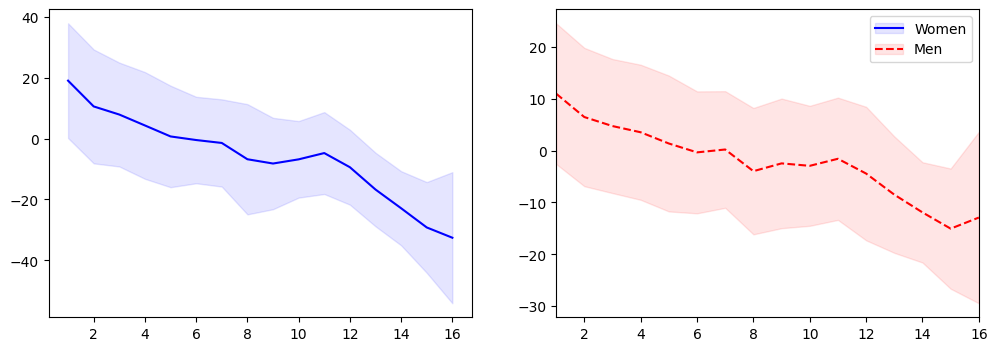

In [36]:
def plot_seed_point_diff():
    # Obtendo a diferença de pontos entre os times em função do seed, separando por homens e mulheres
    tmpmean = tourney_data.pivot_table(columns="men_women", index="T1_seed", values="PointDiff", aggfunc="mean").ffill()
    tmpstd = tourney_data.pivot_table(columns="men_women", index="T1_seed", values="PointDiff", aggfunc="std").ffill()

    # Gráfico da diferença de pontos em função do seed, com barras de erro representando o desvio padrão
    fig, axis = plt.subplots(ncols=2, figsize=(12, 4))
    (line_1,) = axis[0].plot(tmpmean.index, tmpmean[0], "b-")
    fill_1 = axis[0].fill_between(tmpmean.index, tmpmean[0] - tmpstd[0], tmpmean[0] + tmpstd[0], color="b", alpha=0.1)
    (line_2,) = axis[1].plot(tmpmean.index, tmpmean[1], "r--")
    fill_2 = axis[1].fill_between(tmpmean.index, tmpmean[1] - tmpstd[1], tmpmean[1] + tmpstd[1], color="r", alpha=0.1)
    plt.margins(x=0)
    plt.legend([(line_1, fill_1), (line_2, fill_2)], ["Women", "Men"])

plot_seed_point_diff()

Pelos gráficos é verificado que os melhores seeds, ou seja, aqueles com números menores, ficam com uma média de PointDiff positiva e mais alta, indicando um bom acúmulo de vitórias.

Percebe-se que o traço cai conforme o seed aumenta, isso indica que, como esperado, seeds piores tendem a ter mais derrotas - menor saldo de pontos.

Além disso, o desvio padrão, observado pela largura das faixas sombreadas, sugere que na categoria Feminino há uma incerteza maior na previsão dos jogos através do *seed* do que no Masculino, onde é encontrado um comportamento um pouco mais consistente.


<h4 id="feature-medias-das-estatisticas-dos-jogos">2. Features: Médias das Estatísticas dos Jogos</h4>

Para todos os jogos de cada equipe em uma temporada regular, os dados estatísticos podem ser **agregados em uma média** para montar uma feature geralizando cada característica.

In [37]:
def add_avg_stats_features():
    """
    Calcula a média das estatísticas de cada time em cada temporada.
    """
    # Colunas de estatísticas dos jogos, separadas por time, para usar como features
    stats_cols = [
        "T1_Score", "T1_FGM", "T1_FGA", "T1_FGM3", "T1_FGA3", "T1_FTM", "T1_FTA",
        "T1_OR", "T1_DR", "T1_Ast", "T1_TO", "T1_Stl", "T1_Blk", "T1_PF",
        "T2_Score", "T2_FGM", "T2_FGA", "T2_FGM3", "T2_FGA3", "T2_FTM", "T2_FTA",
        "T2_OR", "T2_DR", "T2_Ast", "T2_TO", "T2_Stl", "T2_Blk", "T2_PF",
        "PointDiff",
    ]

    # Calculando a média das estatísticas de cada time em cada temporada, para usar como features adicionais
    ss = regular_data.groupby(["Season", "T1_TeamID"])[stats_cols].agg("mean").reset_index()

    # Criando dataframe separado para as estatísticas do time 1 e renomeando as colunas das médias
    ss_T1 = ss.copy()
    ss_T1.columns = ["T1_avg_" + x.replace("T1_", "").replace("T2_", "opponent_") for x in list(ss_T1.columns)]
    # Corrigindo os nomes das colunas de temporada e ID do time, que não se aplica como média
    ss_T1 = ss_T1.rename({"T1_avg_Season": "Season", "T1_avg_TeamID": "T1_TeamID"}, axis=1)

    ss_T2 = ss.copy()
    ss_T2.columns = ["T2_avg_" + x.replace("T1_", "").replace("T2_", "opponent_") for x in list(ss_T2.columns)]
    ss_T2 = ss_T2.rename({"T2_avg_Season": "Season", "T2_avg_TeamID": "T2_TeamID"}, axis=1)

    # Fazendo o merge das estatísticas médias de ambos os times com os dados dos jogos
    output = pd.merge(tourney_data, ss_T1, on=["Season", "T1_TeamID"], how="left")
    output = pd.merge(output, ss_T2, on=["Season", "T2_TeamID"], how="left")
    
    return output

In [38]:
# Adicionando as features de estatísticas médias dos times nos dados do torneio
tourney_data = add_avg_stats_features()
tourney_data

,Season,T1_TeamID,T2_TeamID,PointDiff,win,men_women,T1_seed,T2_seed,Seed_diff,T1_avg_Score,T1_avg_FGM,T1_avg_FGA,T1_avg_FGM3,T1_avg_FGA3,T1_avg_FTM,T1_avg_FTA,T1_avg_OR,T1_avg_DR,T1_avg_Ast,T1_avg_TO,T1_avg_Stl,T1_avg_Blk,T1_avg_PF,T1_avg_opponent_Score,T1_avg_opponent_FGM,T1_avg_opponent_FGA,T1_avg_opponent_FGM3,T1_avg_opponent_FGA3,T1_avg_opponent_FTM,T1_avg_opponent_FTA,T1_avg_opponent_OR,T1_avg_opponent_DR,T1_avg_opponent_Ast,T1_avg_opponent_TO,T1_avg_opponent_Stl,T1_avg_opponent_Blk,T1_avg_opponent_PF,T1_avg_PointDiff,T2_avg_Score,T2_avg_FGM,T2_avg_FGA,T2_avg_FGM3,T2_avg_FGA3,T2_avg_FTM,T2_avg_FTA,T2_avg_OR,T2_avg_DR,T2_avg_Ast,T2_avg_TO,T2_avg_Stl,T2_avg_Blk,T2_avg_PF,T2_avg_opponent_Score,T2_avg_opponent_FGM,T2_avg_opponent_FGA,T2_avg_opponent_FGM3,T2_avg_opponent_FGA3,T2_avg_opponent_FTM,T2_avg_opponent_FTA,T2_avg_opponent_OR,T2_avg_opponent_DR,T2_avg_opponent_Ast,T2_avg_opponent_TO,T2_avg_opponent_Stl,T2_avg_opponent_Blk,T2_avg_opponent_PF,T2_avg_PointDiff
0,2003,1421,1411,7.111111,1,1,16,16,0,69.615326,23.847510,55.639847,6.348659,17.658238,15.571648,20.428352,12.011494,22.652874,12.740230,15.931034,6.927969,2.937165,18.769349,76.947893,27.242146,59.712644,7.459004,20.307280,15.004598,22.157854,13.463602,22.401533,15.563218,12.568582,8.679693,4.141762,18.265134,-7.332567,72.533333,24.644444,55.051852,5.911111,18.437037,17.333333,27.929630,13.103704,24.677778,14.140741,15.166667,6.407407,2.222222,18.211111,70.585185,25.581481,60.140741,7.507407,23.051852,11.914815,18.655556,11.881481,22.781481,13.718519,14.259259,7.977778,2.596296,21.533333,1.948148
1,2003,1112,1436,29.000000,1,1,1,16,15,84.511905,30.067460,65.087302,6.984127,19.857143,17.392857,24.813492,15.051587,27.440476,17.488095,14.666667,8.396825,4.186508,17.587302,69.531746,26.115079,64.107143,6.253968,19.797619,11.047619,17.503968,12.980159,23.067460,15.341270,16.738095,5.904762,2.369048,21.888889,14.980159,67.255172,24.634483,55.427586,5.241379,15.310345,12.744828,19.379310,12.903448,25.565517,14.096552,13.993103,6.841379,2.958621,15.703448,62.565517,22.600000,54.696552,7.034483,21.344828,10.331034,15.482759,9.517241,21.641379,13.158621,12.910345,7.082759,3.655172,17.772414,4.689655
2,2003,1113,1272,13.000000,1,1,10,7,-3,75.344828,27.003831,56.436782,3.977011,12.475096,17.360153,25.877395,13.501916,23.111111,15.448276,13.881226,5.164751,4.191571,19.260536,68.574713,24.574713,55.176245,5.398467,15.766284,14.026820,20.375479,10.931034,20.367816,13.946360,15.402299,5.950192,3.908046,22.624521,6.770115,74.210728,26.183908,59.762452,6.969349,19.996169,14.873563,22.766284,14.019157,25.846743,16.555556,13.739464,7.363985,5.042146,18.693487,65.517241,23.164751,57.593870,5.854406,18.218391,13.333333,20.659004,12.295019,23.482759,13.237548,15.019157,7.252874,3.153257,19.827586,8.693487
3,2003,1141,1166,6.000000,1,1,11,6,-5,79.344828,26.620690,52.689655,6.827586,17.931034,19.275862,25.172414,10.586207,23.275862,15.620690,18.241379,7.103448,4.000000,20.965517,73.241379,26.344828,57.931034,4.965517,13.896552,15.586207,21.965517,12.241379,18.896552,11.793103,16.068966,8.448276,2.482759,21.689655,6.103448,79.006734,28.619529,57.289562,7.942761,20.424242,13.824916,19.952862,10.848485,23.097643,16.784512,13.309764,8.370370,4.427609,17.205387,64.107744,23.797980,55.148148,4.868687,14.282828,11.643098,16.619529,11.020202,21.289562,12.329966,17.006734,6.306397,2.569024,19.323232,14.898990
4,2003,1143,1301,1.777778,1,1,8,9,1,73.636015,27.015326,57.946360,6.314176,16.789272,13.291188,19.371648,11.114943,24.095785,15.816092,14.019157,6.455939,2.758621,16.888889,68.923372,25.072797,58.114943,7.034483,21.237548,11.743295,17.214559,11.049808,22.659004,15.881226,14.708812,5.865900,2.482759,18.919540,4.712644,72.122222,24.248148,53.129630,7.940741,22.429630,15.685185,20.385185,9.700000,21.907407,14.614815,14.129630,7.737037,3.048148,18.603704,67.751852,23.337037,52.925926,5.703704,16.903704,15.374074,21.129630,10.514815,21.348148,12.511111,14.581481,7.418519,2.811111,19.262963,4.370370

<h4 id="feature-elo-da-equipe">3. Feature: Elo da equipe</h4>

O **Método de Avaliação por Elo** é um sistema que leva em conta os dados sequenciais dos jogos ao longo do tempo para criar uma métrica acumulada da força do time.

- Cada time começa com um elo incial
- Após cada jogo o valor do elo de cada um é atualizado

O **resultado esperado** de uma partida é obtido de um fórmula que calcula a probabilidade de A vencer B com base na diferença dos seus elos:

```py
1 / (1 + 10 ** ((elo_b - elo_a) / 400))
```

Quanto maior a diferença entre os elos, mais distante dos 0.5 este valor fica.

Com base nisso, há a **mudança no elo** por jogo:

```py
change_in_elo = k_factor * (1 - expected_win)
```

Ou seja, um time que já tem alta chance de vencer o jogo tem pouca mudança quando vence,<br>
mas quando um time fraco (baixa expectativa de vitória) ganha um jogo, a mudança é elevada.

In [39]:
def add_elo_features(base_elo=1000, elo_width=400, k_factor=100):
    """
    Função para incluir o Elo de ambos os times como features adicionais no dataframe de dados dos jogos.
        - base_elo: Elo inicial para todos os times
        - elo_width: Parâmetro de controle da diferença de Elo
        - k_factor: Parâmetro de controle da magnitude da atualização do Elo após cada jogo
    """

    def expected_result(elo_a, elo_b):
        """ Função que calcula a probabilidade de vitória do time 1 contra o time 2, dado o Elo de ambos os times """
        return 1.0 / (1 + 10 ** ((elo_b - elo_a) / elo_width))
    
    
    def update_elo(winner_elo, loser_elo):
        """ Função que calcula a atualização do Elo de ambos os times após um jogo """
        expected_win = expected_result(winner_elo, loser_elo)
        change_in_elo = k_factor * (1 - expected_win)
        winner_elo += change_in_elo
        loser_elo -= change_in_elo
        
        return winner_elo, loser_elo


    elos = []
    for season in sorted(set(seeds["Season"])):  # Itera sobre as temporadas
        ss = regular_data.loc[regular_data["Season"] == season]
        ss = ss.loc[ss["win"] == 1].reset_index(drop=True) # Considerando apenas os jogos onde o time 1 venceu, para atualizar o Elo de ambos os times corretamente
        teams = set(ss["T1_TeamID"]) | set(ss["T2_TeamID"]) # Obtendo o conjunto de times que jogaram na temporada, para inicializar o Elo de cada time

        elo = dict(zip(teams, [base_elo] * len(teams))) # Inicializando o Elo de cada time com o valor base

        for i in range(ss.shape[0]):
            w_team, l_team = ss.loc[i, "T1_TeamID"], ss.loc[i, "T2_TeamID"] # Obtendo os IDs do time vencedor e perdedor do jogo
            w_elo, l_elo = elo[w_team], elo[l_team]   # Obtendo o Elo atual de ambos os times

            w_elo_new, l_elo_new = update_elo(w_elo, l_elo)  # Calculando o novo Elo de ambos os times após o jogo

            elo[w_team] = w_elo_new  # Atualizando o Elo do time vencedor
            elo[l_team] = l_elo_new  # Atualizando o Elo do time perdedor

        elo = pd.DataFrame.from_dict(elo, orient="index").reset_index()  # Convertendo o dicionário de Elo para um dataframe
        elo = elo.rename({"index": "TeamID", 0: "elo"}, axis=1)  # Renomeando as colunas do dataframe de Elo
        elo["Season"] = season    # Adicionando a coluna de temporada ao dataframe de Elo
        elos.append(elo)
        
    elos = pd.concat(elos)  # Concatenando os dataframes de Elo de todas as temporadas em um único dataframe

    # Incluindo o Elo de ambos os times como features adicionais no dataframe de dados dos jogos
    elos_T1 = elos.copy().rename({"TeamID": "T1_TeamID", "elo": "T1_elo"}, axis=1)
    elos_T2 = elos.copy().rename({"TeamID": "T2_TeamID", "elo": "T2_elo"}, axis=1)
                                
    output = pd.merge(tourney_data, elos_T1, on=["Season", "T1_TeamID"], how="left")
    output = pd.merge(output, elos_T2, on=["Season", "T2_TeamID"], how="left")

    # Criando uma feature adicional de diferença de Elo entre os times
    output["elo_diff"] = output["T1_elo"] - output["T2_elo"]
        
    return output

In [40]:
# Adicionando as features de Elo dos times nos dados do torneio
tourney_data = add_elo_features()

<h4 id="feature-qualidade-da-equipe">4. Feature: Qualidade da equipe</h4>

A qualidade de um time em uma temporada pode ser avaliada por meio de um Modelo de Regressão Linear Generalizada (GLM), onde o coeficiente representa a qualidade do time.


##### Funcionamento do GLM

O modelo realiza one-hot encoding das equipes, adicionando uma coluna por id específico.

Isso gera um sistema de equações onde cada linha é um jogo, e as colunas representam os times envolvidos:

| Jogo   | 1001  | 1002 | 1003 | Resultado |
| ------ | -- | -- | -- | --------- |
| 1001 vs 1002 | +1 | -1 | 0  | 10        |
| 1002 vs 1003 | 0  | +1 | -1 | 5         |
| 1001 vs 1003 | +1 | 0  | -1 | 5         |

A fórmula usada `PointDiff ~ -1 + T1_TeamID + T2_TeamID` é interpretada como:

$$PointDiff = coef(T1\_time) + coef(T2\_time)$$

Onde o coeficiente representa na prática a qualidade do time, ou seja, o quanto ele contribui para a diferença de pontos em um jogo.

$$PointDiff ≈ qualidade(T1) - qualidade(T2)$$

Nesse sentido o modelo resolverá o sistema ajustando e encontrando um valor de coeficiente para cada `Team_ID` de modo a satisfazer todos os jogos.

_Sintaxe da fórmula_:
- *`PointDiff` → o valor a ser previsto*
- *`T1_TeamID` → identificação do time 1*
- *`T2_TeamID` → identificação do time 2*
- *`-1` → remove constante*
- *`+` → adiciona variáveis*

*PointDiff ≈ constante + qualidade(T1) - qualidade(T2)*

In [41]:
def add_quality_features():
    """
    Função para incluir features de qualidade dos times
    """

    def team_quality(season, men_women):
        """
        Função que calcula a qualidade de cada time em uma temporada, 
        usando um modelo de regressão linear generalizada (GLM) 
        onde o coeficiente representa a qualidade do time.
        """
        # Efeitos mistos: PointDiff = efeito(T1) - efeito(T2)
        formula = "PointDiff~-1+T1_TeamID+T2_TeamID"
        glm = sm.GLM.from_formula(
            formula=formula,
            data=dt.loc[(dt["Season"] == season) & (dt["men_women"] == men_women), :],
            family=sm.families.Gaussian(),
        ).fit()
        
        quality = pd.DataFrame(glm.params).reset_index()
        quality.columns = ["TeamID", "quality"]
        quality["quality"] = quality["quality"]
        quality["Season"] = season

        # 
        quality = quality.loc[quality.TeamID.str.contains("T1_")].reset_index(drop=True)
        quality["TeamID"] = quality["TeamID"].apply(lambda x: x[10:14]).astype(int)

        return quality


    # Extraindo o seed, a temporada e o ID do time, e duplicando para ter uma linha para cada time
    seeds_T1 = seeds[["Season", "TeamID", "seed"]].copy()
    seeds_T2 = seeds[["Season", "TeamID", "seed"]].copy()

    # Renomeando as colunas para facilitar o merge com os dados dos jogos
    seeds_T1.columns = ["Season", "T1_TeamID", "T1_seed"]
    seeds_T2.columns = ["Season", "T2_TeamID", "T2_seed"]

    # Criando label 'temporada/time' para facilitar identificação
    regular_data["ST1"] = regular_data.apply(lambda t: str(int(t["Season"])) + "/" + str(int(t["T1_TeamID"])), axis=1)
    regular_data["ST2"] = regular_data.apply(lambda t: str(int(t["Season"])) + "/" + str(int(t["T2_TeamID"])), axis=1)
    seeds_T1["ST1"] = seeds_T1.apply(lambda t: str(int(t["Season"])) + "/" + str(int(t["T1_TeamID"])), axis=1)
    seeds_T2["ST2"] = seeds_T2.apply(lambda t: str(int(t["Season"])) + "/" + str(int(t["T2_TeamID"])), axis=1)

    # Coletando os times do torneio
    st = set(seeds_T1["ST1"]) | set(seeds_T2["ST2"])
    
    # Incluindo os times que conseguiram vencer um time do torneio pelo menos uma vez, mesmo que não tenham se classificado para o torneio
    st = st | set(regular_data.loc[(regular_data["T1_Score"] > regular_data["T2_Score"]) & 
                                   (regular_data["ST2"].isin(st)), "ST1"])
    


    # Considerando apenas os jogos onde pelo menos um dos times ou participou do torneio ou ganhou de um time que participou do torneio
    dt = regular_data.loc[regular_data["ST1"].isin(st) | regular_data["ST2"].isin(st)]

    dt["T1_TeamID"] = dt["T1_TeamID"].astype(str)
    dt["T2_TeamID"] = dt["T2_TeamID"].astype(str)

    # Atribuindo um ID de time "0000" para os times que não participaram do torneio e não venceram nenhum time do torneio,
    # para que eles sejam considerados como times de qualidade muito baixa no modelo
    dt.loc[~dt["ST1"].isin(st), "T1_TeamID"] = "0000"
    dt.loc[~dt["ST2"].isin(st), "T2_TeamID"] = "0000"

    glm_quality = []
    seasons = sorted(set(seeds["Season"]))
    for s in tqdm.tqdm(seasons, unit="season"):
        if s >= 2010:  # Temporada mínima para mulheres, de acordo com a disponibilidade de dados
            glm_quality.append(team_quality(s, 0))
        if s >= 2003:  # Temporada mínima para homens
            glm_quality.append(team_quality(s, 1))

    glm_quality = pd.concat(glm_quality).reset_index(drop=True)

    # Incluindo a qualidade de ambos os times como features adicionais no dataframe de dados dos jogos
    glm_quality_T1 = glm_quality.copy()
    glm_quality_T2 = glm_quality.copy()
    glm_quality_T1.columns = ["T1_TeamID", "T1_quality", "Season"]
    glm_quality_T2.columns = ["T2_TeamID", "T2_quality", "Season"]

    # Fazendo o merge da qualidade dos times com os dados dos jogos
    output = pd.merge(tourney_data, glm_quality_T1, on=["Season", "T1_TeamID"], how="left")
    output = pd.merge(output, glm_quality_T2, on=["Season", "T2_TeamID"], how="left")

    # Criando uma feature adicional de diferença de qualidade entre os times
    output["diff_quality"] = output["T1_quality"] - output["T2_quality"]

    return output

In [42]:
# Adicionando as features de Qualidade dos times nos dados do torneio
tourney_data = add_quality_features()
tourney_data

100%|██████████| 22/22 [01:01<00:00,  2.80s/season]


,Season,T1_TeamID,T2_TeamID,PointDiff,win,men_women,T1_seed,T2_seed,Seed_diff,T1_avg_Score,T1_avg_FGM,T1_avg_FGA,T1_avg_FGM3,T1_avg_FGA3,T1_avg_FTM,T1_avg_FTA,T1_avg_OR,T1_avg_DR,T1_avg_Ast,T1_avg_TO,T1_avg_Stl,T1_avg_Blk,T1_avg_PF,T1_avg_opponent_Score,T1_avg_opponent_FGM,T1_avg_opponent_FGA,T1_avg_opponent_FGM3,T1_avg_opponent_FGA3,T1_avg_opponent_FTM,T1_avg_opponent_FTA,T1_avg_opponent_OR,T1_avg_opponent_DR,T1_avg_opponent_Ast,T1_avg_opponent_TO,T1_avg_opponent_Stl,T1_avg_opponent_Blk,T1_avg_opponent_PF,T1_avg_PointDiff,T2_avg_Score,T2_avg_FGM,T2_avg_FGA,T2_avg_FGM3,T2_avg_FGA3,T2_avg_FTM,T2_avg_FTA,T2_avg_OR,T2_avg_DR,T2_avg_Ast,T2_avg_TO,T2_avg_Stl,T2_avg_Blk,T2_avg_PF,T2_avg_opponent_Score,T2_avg_opponent_FGM,T2_avg_opponent_FGA,T2_avg_opponent_FGM3,T2_avg_opponent_FGA3,T2_avg_opponent_FTM,T2_avg_opponent_FTA,T2_avg_opponent_OR,T2_avg_opponent_DR,T2_avg_opponent_Ast,T2_avg_opponent_TO,T2_avg_opponent_Stl,T2_avg_opponent_Blk,T2_avg_opponent_PF,T2_avg_PointDiff,T1_elo,T2_elo,elo_diff,T1_quality,T2_quality,diff_quality
0,2003,1421,1411,7.111111,1,1,16,16,0,69.615326,23.847510,55.639847,6.348659,17.658238,15.571648,20.428352,12.011494,22.652874,12.740230,15.931034,6.927969,2.937165,18.769349,76.947893,27.242146,59.712644,7.459004,20.307280,15.004598,22.157854,13.463602,22.401533,15.563218,12.568582,8.679693,4.141762,18.265134,-7.332567,72.533333,24.644444,55.051852,5.911111,18.437037,17.333333,27.929630,13.103704,24.677778,14.140741,15.166667,6.407407,2.222222,18.211111,70.585185,25.581481,60.140741,7.507407,23.051852,11.914815,18.655556,11.881481,22.781481,13.718519,14.259259,7.977778,2.596296,21.533333,1.948148,1004.511285,1006.068840,-1.557555,-3.099741,2.115495,-5.215236
1,2003,1112,1436,29.000000,1,1,1,16,15,84.511905,30.067460,65.087302,6.984127,19.857143,17.392857,24.813492,15.051587,27.440476,17.488095,14.666667,8.396825,4.186508,17.587302,69.531746,26.115079,64.107143,6.253968,19.797619,11.047619,17.503968,12.980159,23.067460,15.341270,16.738095,5.904762,2.369048,21.888889,14.980159,67.255172,24.634483,55.427586,5.241379,15.310345,12.744828,19.379310,12.903448,25.565517,14.096552,13.993103,6.841379,2.958621,15.703448,62.565517,22.600000,54.696552,7.034483,21.344828,10.331034,15.482759,9.517241,21.641379,13.158621,12.910345,7.082759,3.655172,17.772414,4.689655,1428.100063,1163.408934,264.691130,27.707625,8.728406,18.979218
2,2003,1113,1272,13.000000,1,1,10,7,-3,75.344828,27.003831,56.436782,3.977011,12.475096,17.360153,25.877395,13.501916,23.111111,15.448276,13.881226,5.164751,4.191571,19.260536,68.574713,24.574713,55.176245,5.398467,15.766284,14.026820,20.375479,10.931034,20.367816,13.946360,15.402299,5.950192,3.908046,22.624521,6.770115,74.210728,26.183908,59.762452,6.969349,19.996169,14.873563,22.766284,14.019157,25.846743,16.555556,13.739464,7.363985,5.042146,18.693487,65.517241,23.164751,57.593870,5.854406,18.218391,13.333333,20.659004,12.295019,23.482759,13.237548,15.019157,7.252874,3.153257,19.827586,8.693487,1169.181611,1344.907733,-175.726122,19.701429,19.004846,0.696583
3,2003,1141,1166,6.000000,1,1,11,6,-5,79.344828,26.620690,52.689655,6.827586,17.931034,19.275862,25.172414,10.586207,23.275862,15.620690,18.241379,7.103448,4.000000,20.965517,73.241379,26.344828,57.931034,4.965517,13.896552,15.586207,21.965517,12.241379,18.896552,11.793103,16.068966,8.448276,2.482759,21.689655,6.103448,79.006734,28.619529,57.289562,7.942761,20.424242,13.824916,19.952862,10.848485,23.097643,16.784512,13.309764,8.370370,4.427609,17.205387,64.107744,23.797980,55.148148,4.868687,14.282828,11.643098,16.619529,11.020202,21.289562,12.329966,17.006734,6.306397,2.569024,19.323232,14.898990,1358.162841,1382.642338,-24.479498,10.679634,20.664199,-9.984565
4,2003,1143,1301,1.777778,1,1,8,9,1,73.636015,27.015326,57.946360,6.314176,16.789272,13.291188,19.371648,11.114943,24.095785,15.816092,14.019157,6.455939,2.758621,16.888889,68.923372,25.072797,58.114943,7.034483,21.237548,11.743295,17.214559,11.049808,22.659004,15.881226,14.708812,5.8

In [43]:
tourney_data

,Season,T1_TeamID,T2_TeamID,PointDiff,win,men_women,T1_seed,T2_seed,Seed_diff,T1_avg_Score,T1_avg_FGM,T1_avg_FGA,T1_avg_FGM3,T1_avg_FGA3,T1_avg_FTM,T1_avg_FTA,T1_avg_OR,T1_avg_DR,T1_avg_Ast,T1_avg_TO,T1_avg_Stl,T1_avg_Blk,T1_avg_PF,T1_avg_opponent_Score,T1_avg_opponent_FGM,T1_avg_opponent_FGA,T1_avg_opponent_FGM3,T1_avg_opponent_FGA3,T1_avg_opponent_FTM,T1_avg_opponent_FTA,T1_avg_opponent_OR,T1_avg_opponent_DR,T1_avg_opponent_Ast,T1_avg_opponent_TO,T1_avg_opponent_Stl,T1_avg_opponent_Blk,T1_avg_opponent_PF,T1_avg_PointDiff,T2_avg_Score,T2_avg_FGM,T2_avg_FGA,T2_avg_FGM3,T2_avg_FGA3,T2_avg_FTM,T2_avg_FTA,T2_avg_OR,T2_avg_DR,T2_avg_Ast,T2_avg_TO,T2_avg_Stl,T2_avg_Blk,T2_avg_PF,T2_avg_opponent_Score,T2_avg_opponent_FGM,T2_avg_opponent_FGA,T2_avg_opponent_FGM3,T2_avg_opponent_FGA3,T2_avg_opponent_FTM,T2_avg_opponent_FTA,T2_avg_opponent_OR,T2_avg_opponent_DR,T2_avg_opponent_Ast,T2_avg_opponent_TO,T2_avg_opponent_Stl,T2_avg_opponent_Blk,T2_avg_opponent_PF,T2_avg_PointDiff,T1_elo,T2_elo,elo_diff,T1_quality,T2_quality,diff_quality
0,2003,1421,1411,7.111111,1,1,16,16,0,69.615326,23.847510,55.639847,6.348659,17.658238,15.571648,20.428352,12.011494,22.652874,12.740230,15.931034,6.927969,2.937165,18.769349,76.947893,27.242146,59.712644,7.459004,20.307280,15.004598,22.157854,13.463602,22.401533,15.563218,12.568582,8.679693,4.141762,18.265134,-7.332567,72.533333,24.644444,55.051852,5.911111,18.437037,17.333333,27.929630,13.103704,24.677778,14.140741,15.166667,6.407407,2.222222,18.211111,70.585185,25.581481,60.140741,7.507407,23.051852,11.914815,18.655556,11.881481,22.781481,13.718519,14.259259,7.977778,2.596296,21.533333,1.948148,1004.511285,1006.068840,-1.557555,-3.099741,2.115495,-5.215236
1,2003,1112,1436,29.000000,1,1,1,16,15,84.511905,30.067460,65.087302,6.984127,19.857143,17.392857,24.813492,15.051587,27.440476,17.488095,14.666667,8.396825,4.186508,17.587302,69.531746,26.115079,64.107143,6.253968,19.797619,11.047619,17.503968,12.980159,23.067460,15.341270,16.738095,5.904762,2.369048,21.888889,14.980159,67.255172,24.634483,55.427586,5.241379,15.310345,12.744828,19.379310,12.903448,25.565517,14.096552,13.993103,6.841379,2.958621,15.703448,62.565517,22.600000,54.696552,7.034483,21.344828,10.331034,15.482759,9.517241,21.641379,13.158621,12.910345,7.082759,3.655172,17.772414,4.689655,1428.100063,1163.408934,264.691130,27.707625,8.728406,18.979218
2,2003,1113,1272,13.000000,1,1,10,7,-3,75.344828,27.003831,56.436782,3.977011,12.475096,17.360153,25.877395,13.501916,23.111111,15.448276,13.881226,5.164751,4.191571,19.260536,68.574713,24.574713,55.176245,5.398467,15.766284,14.026820,20.375479,10.931034,20.367816,13.946360,15.402299,5.950192,3.908046,22.624521,6.770115,74.210728,26.183908,59.762452,6.969349,19.996169,14.873563,22.766284,14.019157,25.846743,16.555556,13.739464,7.363985,5.042146,18.693487,65.517241,23.164751,57.593870,5.854406,18.218391,13.333333,20.659004,12.295019,23.482759,13.237548,15.019157,7.252874,3.153257,19.827586,8.693487,1169.181611,1344.907733,-175.726122,19.701429,19.004846,0.696583
3,2003,1141,1166,6.000000,1,1,11,6,-5,79.344828,26.620690,52.689655,6.827586,17.931034,19.275862,25.172414,10.586207,23.275862,15.620690,18.241379,7.103448,4.000000,20.965517,73.241379,26.344828,57.931034,4.965517,13.896552,15.586207,21.965517,12.241379,18.896552,11.793103,16.068966,8.448276,2.482759,21.689655,6.103448,79.006734,28.619529,57.289562,7.942761,20.424242,13.824916,19.952862,10.848485,23.097643,16.784512,13.309764,8.370370,4.427609,17.205387,64.107744,23.797980,55.148148,4.868687,14.282828,11.643098,16.619529,11.020202,21.289562,12.329966,17.006734,6.306397,2.569024,19.323232,14.898990,1358.162841,1382.642338,-24.479498,10.679634,20.664199,-9.984565
4,2003,1143,1301,1.777778,1,1,8,9,1,73.636015,27.015326,57.946360,6.314176,16.789272,13.291188,19.371648,11.114943,24.095785,15.816092,14.019157,6.455939,2.758621,16.888889,68.923372,25.072797,58.114943,7.034483,21.237548,11.743295,17.214559,11.049808,22.659004,15.881226,14.708812,5.8

## Seleção das Features

O `tourney_data` é o conjunto de dados que será utilizado para gerar as previsões.

Porém, é necessário desconsiderar algumas colunas:

- **`Season`** - A temporada do jogo não é uma informação relevante para a previsão, pois o modelo deve ser capaz de generalizar para qualquer temporada, e não apenas para as temporadas presentes nos dados de treinamento.

- **`T1_TeamID` e `T2_TeamID`** - Os IDs dos times não possuem um significado intrínseco, ou seja, eles não indicam a força ou qualidade da equipe, e sim apenas uma identificação única.

- **`PointDiff`** - A diferença de pontos é uma informação que só é conhecida após o jogo, e portanto não pode ser utilizada como feature para prever o resultado.

In [44]:
features = tourney_data.columns.drop(['Season', 'PointDiff', 'T2_TeamID', 'T1_TeamID', 'win'])

Finalmente, obtém-se o dataset objetivado na seção de [Pré-processamento](#problema), contendo apenas as features relevantes para a previsão e o target.

In [45]:
X_tourney = tourney_data[features]
y_tourney = tourney_data['win']

In [46]:

features = [
    ### EASY FEATURES ###
    "men_women",    
    "T1_seed",
    "T2_seed",
    "Seed_diff",
    ### MEDIUM FEATURES ###
    "T1_avg_Score",
    #"T1_avg_FGM",
    "T1_avg_FGA",
    #"T1_avg_FGM3",
    #"T1_avg_FGA3",
    #"T1_avg_FTM",
    #"T1_avg_FTA",
    "T1_avg_OR",
    "T1_avg_DR",
    #"T1_avg_Ast",
    #"T1_avg_TO",
    #"T1_avg_Stl",
    "T1_avg_Blk",
    "T1_avg_PF",
    #"T1_avg_opponent_Score",
    #"T1_avg_opponent_FGM",
    "T1_avg_opponent_FGA",
    #"T1_avg_opponent_FGM3",
    #"T1_avg_opponent_FGA3",
    #"T1_avg_opponent_FTM",
    #"T1_avg_opponent_FTA",
    #"T1_avg_opponent_OR",
    #"T1_avg_opponent_DR",
    #"T1_avg_opponent_Ast",
    #"T1_avg_opponent_TO",
    #"T1_avg_opponent_Stl",
    "T1_avg_opponent_Blk",
    "T1_avg_opponent_PF",
    # "T1_avg_PointDiff",
    "T2_avg_Score",
    #"T2_avg_FGM",
    "T2_avg_FGA",
    #"T2_avg_FGM3",
    #"T2_avg_FGA3",
    #"T2_avg_FTM",
    #"T2_avg_FTA",
    "T2_avg_OR",
    "T2_avg_DR",
    #"T2_avg_Ast",
    #"T2_avg_TO",
    #"T2_avg_Stl",
    "T2_avg_Blk",
    "T2_avg_PF",
    #"T2_avg_opponent_Score",
    #"T2_avg_opponent_FGM",
    "T2_avg_opponent_FGA",
    #"T2_avg_opponent_FGM3",
    #"T2_avg_opponent_FGA3",
    #"T2_avg_opponent_FTM",
    #"T2_avg_opponent_FTA",
    #"T2_avg_opponent_OR",
    #"T2_avg_opponent_DR",
    #"T2_avg_opponent_Ast",
    #"T2_avg_opponent_TO",
    #"T2_avg_opponent_Stl",
    "T2_avg_opponent_Blk",
    "T2_avg_opponent_PF",
    # "T2_avg_PointDiff",
    ### HARD FEATURES ###
    "T1_elo",
    "T2_elo",    
    "elo_diff",
    ### HARDEST FEATURES ###
    "T1_quality",
    "T2_quality",
    "diff_quality",
]

print(f"Número de features: {len(features)}")

# Seleção final
X_tourney = tourney_data[features]
y_tourney = tourney_data['win']

Número de features: 28


## Avaliação dos Hiperparâmetros

Abaixo foi feita uma função auxiliar para exibir os resultados da avaliação de hiperparâmetros e otimizar a busca por meio do Optuna, utilizando o Brier Score como métrica de avaliação.

In [ ]:
def show_results(study, model_name):
    # Mostrar resultados
    print("\n" + "="*60)
    print(f"MELHORES HIPERPARÂMETROS ENCONTRADOS{' - ' + model_name if model_name else ''}")
    print("="*60)

    completed_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]

    if not completed_trials:
        print("Nenhum trial foi completado. Verifique study.trials para detalhes de falha.")
    else:
        best_params = study.best_params
        for key, value in best_params.items():
            print(f"{key}: {value}")
        print(f"\nMelhor Brier Score: {study.best_value:.4f}")


def optimize_hyperparameters(study_name, model_name, objective, n_trials=50):
    """Função para otimizar os hiperparâmetros de um modelo usando Optuna"""
    # Criar estudo Optuna
    study = optuna.create_study(
        direction='minimize',  # Minimizar Brier Score
        sampler=TPESampler(seed=RANDOM_STATE),
        study_name=study_name
    )

    # Executar otimização
    print(f"Executando {n_trials} tentativas...")

    study.optimize(
        lambda trial: objective(trial, X_tourney, y_tourney),
        n_trials=n_trials,
        n_jobs=1,
        show_progress_bar=False
    )

    print("Otimização concluída!")
    show_results(study, model_name)

    return study.best_params

### Criação do Método de Avaliação

O **brier score** é uma métrica de avaliação para modelos de classificação probabilística.

É calculando pela média do quadrado da diferença entre as probabilidades previstas e os resultados reais dos jogos, onde um valor mais baixo indica uma melhor calibração das probabilidades:
$$BrierScore = \frac{1}{N} \sum_{i=1}^{N} (f_i - o_i)^2$$

- $N$ é o número total de jogos previstos
- $f_i$ é a probabilidade prevista para a vitória do time A para a i-ésima previsão
- $o_i$ é o resultado real do jogo (1 = time A, 0 = time B)

Por exemplo,
$$
\begin{aligned}
&y_{\text{true}} = [1, 0, 1] \\
&y_{\text{pred}} = [0.9, 0.1, 0.8] \\
&brier_{\text{score}} = \frac{1}{3} ((0.9 - 1)^2 + (0.1 - 0)^2 + (0.8 - 1)^2) = 0.02
\end{aligned}
$$

O brier score **varia entre 0 e 1**, onde quanto mais baixo um valor, melhor a calibração.


In [47]:
# Função de avaliação personalizada para o Optuna, usando o Brier Score como métrica
def brier_score_scorer(y_true, y_pred):
    """Calcula Brier Score para validação cruzada"""
    return -brier_score_loss(y_true, y_pred)  # Negativo pois o Optuna maximiza

# Criar scorer personalizado
brier_scorer = make_scorer(brier_score_loss, greater_is_better=False, response_method='predict_proba')

### Abordagem 1 - Regressão Logística<a id="hiperparametros-regressao-logistica"></a>

In [87]:
def create_logistic_regression_pipeline(params):
    """Cria pipeline com normalização e regressão logística"""
    steps = []

    # Imputação 
    if params.get('impute', False):
        steps.append(('imputer', SimpleImputer(strategy=params['impute_strategy'])))
    # Scaling
    if params.get('scale', False):
        steps.append(('scaler', RobustScaler() if params.get('scaler_type') == 'robust' 
                     else StandardScaler()))
        
    # Classificador de regressão logística
    lr_params = {
        'C': params['C'],
        'penalty': params['penalty'],
        'solver': params['solver'],
        'max_iter': params.get('max_iter', 1000),
        'class_weight': params.get('class_weight', 'balanced'),
        'random_state': RANDOM_STATE
    }

    steps.append(('classifier', LogisticRegression(**lr_params)))
    return Pipeline(steps)


def objective_logistic_regression(trial, X, y):
    """Função objetivo para o Optuna - Regressão Logística"""
    
    # Hiperparâmetros a serem otimizados
    params = {
        'C': trial.suggest_float('C', 1e-4, 1e2, log=True),
        'penalty': trial.suggest_categorical('penalty', ['l1', 'l2']),
        'solver': trial.suggest_categorical('solver', ['liblinear', 'saga']),
        'impute_strategy': trial.suggest_categorical('impute_strategy', ['mean', 'median']),
        'scaler_type': trial.suggest_categorical('scaler_type', ['standard', 'robust']),
        'max_iter': trial.suggest_int('max_iter', 500, 2000, step=500),
    }
    
    # Class_weight não é suportado por todos os solvers com penalty l1
    if params['penalty'] == 'l1' and params['solver'] == 'saga':
        params['class_weight'] = trial.suggest_categorical('class_weight', [None, 'balanced'])
    else:
        params['class_weight'] = 'balanced'
    
    # Criar pipeline
    pipeline = create_logistic_regression_pipeline(params)
    
    # StratifiedKFold reduz risco de folds sem ambas as classes
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    
    # Calcular cross-validation score
    try:
        scores = cross_val_score(
            pipeline,
            X.replace([np.inf, -np.inf], np.nan),
            y,
            cv=cv,
            scoring=brier_scorer,
            n_jobs=-1
        )
        score = float(np.mean(-scores))  # Brier Score real
        if not np.isfinite(score):
            raise ValueError('Score inválido (nan/inf)')

        return score
    except Exception as e:
        trial.set_user_attr('failure_reason', str(e))
        return 1.0  # Penaliza configurações problemáticas sem quebrar o estudo

In [ ]:
best_params_lr = optimize_hyperparameters(
    'logistic_regression_optimization',
    "REGRESSÃO LOGÍSTICA",
    objective_logistic_regression,
    50
)

Executando 50 tentativas...


### Abordagem 2 - LightGBM<a id="hiperparametros-lightgbm"></a>

In [89]:
def create_lightgbm_pipeline(params):
    """Cria pipeline com LightGBM"""
    steps = []
    
    # Imputação 
    if params.get('impute', False):
        steps.append(('imputer', SimpleImputer(strategy=params['impute_strategy'])))
    
    # Scaling
    if params.get('scale', False):
        steps.append(('scaler', RobustScaler() if params.get('scaler_type') == 'robust' 
                     else StandardScaler()))
    
    # Classificador LightGBM
    lgb_params = {
        'n_estimators': params['n_estimators'],
        'max_depth': params['max_depth'],
        'learning_rate': params['learning_rate'],
        'num_leaves': params['num_leaves'],
        'min_child_samples': params['min_child_samples'],
        'subsample': params['subsample'],
        'colsample_bytree': params['colsample_bytree'],
        'reg_alpha': params['reg_alpha'],
        'reg_lambda': params['reg_lambda'],
        'min_split_gain': params['min_split_gain'],
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbosity': -1,
    }
    
    # Parâmetros adicionais
    if params.get('boosting_type'):
        lgb_params['boosting_type'] = params['boosting_type']
    
    if params.get('class_weight'):
        lgb_params['class_weight'] = params['class_weight']
    
    steps.append(('classifier', lgb.LGBMClassifier(**lgb_params)))
    return Pipeline(steps)


def objective_lightgbm(trial, X, y):
    """Função objetivo para o Optuna - LightGBM"""
    
    # Hiperparâmetros do LightGBM a serem otimizados
    params = {
        # Parâmetros principais
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000, step=50),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 10, 255),
        
        # Parâmetros de regularização
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'min_split_gain': trial.suggest_float('min_split_gain', 0.0, 1.0),
        
        # Parâmetros de pré-processamento (opcionais)
        'impute': trial.suggest_categorical('impute', [True, False]),
        'scale': trial.suggest_categorical('scale', [True, False]),
    }
    
    # Parâmetros condicionais
    if params['impute']:
        params['impute_strategy'] = trial.suggest_categorical('impute_strategy', ['mean', 'median'])
    
    if params['scale']:
        params['scaler_type'] = trial.suggest_categorical('scaler_type', ['standard', 'robust'])
    
    # Parâmetros avançados
    if trial.suggest_categorical('use_advanced', [True, False]):
        params['boosting_type'] = trial.suggest_categorical('boosting_type', ['gbdt', 'dart', 'goss'])
        params['class_weight'] = trial.suggest_categorical('class_weight', [None, 'balanced'])
    
    # Criar pipeline
    pipeline = create_lightgbm_pipeline(params)
    
    # StratifiedKFold reduz risco de folds sem ambas as classes
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    
    # Calcular cross-validation score
    try:
        scores = cross_val_score(
            pipeline, 
            X.replace([np.inf, -np.inf], np.nan),
            y, 
            cv=cv, 
            scoring=brier_scorer,
            n_jobs=-1
        )
        score = float(np.mean(-scores))  # Brier Score real
        if not np.isfinite(score):
            raise ValueError('Score inválido (nan/inf)')
        
        return score
    except Exception as e:
        print(f"Erro no trial: {e}")
        return 1.0   # Penaliza configurações problemáticas sem quebrar o estudo

In [ ]:
best_params_lgb = optimize_hyperparameters(
    'lightgbm_optimization',
    "LIGHTGBM",
    objective_lightgbm,
    50
)

Executando 50 tentativas...
Otimização concluída!

MELHORES HIPERPARÂMETROS ENCONTRADOS - LIGHTGBM
n_estimators: 950
max_depth: 6
learning_rate: 0.09519754482692679
num_leaves: 86
min_child_samples: 54
subsample: 0.7733551396716398
colsample_bytree: 0.5924272277627636
reg_alpha: 5.324289357128436
reg_lambda: 0.09466630153726856
min_split_gain: 0.9394989415641891
impute: True
scale: True
impute_strategy: mean
scaler_type: robust
use_advanced: False

Melhor Brier Score: 0.1695


### Abordagem 3 - XGBoost<a id="hiperparametros-xgboost"></a>

XGBoost lida bem com valores missing e não precisa de scaling, mas mantemos os blocos opcionais por consistência.

In [ ]:
def create_xgb_pipeline(params):
    """Cria pipeline com XGBoost"""
    steps = []

    # Imputação 
    if params.get('impute', False):
        steps.append(('imputer', SimpleImputer(strategy=params['impute_strategy'])))
    # Scaling
    if params.get('scale', False):
        steps.append(('scaler', RobustScaler() if params.get('scaler_type') == 'robust'
                     else StandardScaler()))

    # Classificador XGBoost
    xgb_params = {
        'n_estimators': params['n_estimators'],
        'max_depth': params['max_depth'],
        'learning_rate': params['learning_rate'],
        'min_child_weight': params['min_child_weight'],
        'subsample': params['subsample'],
        'colsample_bytree': params['colsample_bytree'],
        'gamma': params['gamma'],
        'reg_alpha': params['reg_alpha'],
        'reg_lambda': params['reg_lambda'],
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbosity': 0,
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'tree_method': 'hist',
    }

    if params.get('booster'):
        xgb_params['booster'] = params['booster']

    steps.append(('classifier', XGBClassifier(**xgb_params)))
    return Pipeline(steps)


def objective_xgboost(trial, X, y):
    """
    Função objetivo para o Optuna - XGBoost
    """
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000, step=50),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'min_child_weight': trial.suggest_float('min_child_weight', 1.0, 10.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'impute': trial.suggest_categorical('impute', [True, False]),
        'scale': trial.suggest_categorical('scale', [True, False]),
    }

    # Parâmetros avançados (testar esporadicamente)
    if params['impute']:
        params['impute_strategy'] = trial.suggest_categorical('impute_strategy', ['mean', 'median'])

    if params['scale']:
        params['scaler_type'] = trial.suggest_categorical('scaler_type', ['standard', 'robust'])

    if trial.suggest_categorical('use_advanced', [True, False]):
        params['booster'] = trial.suggest_categorical('booster', ['gbtree', 'dart'])

    # Criar pipeline
    pipeline = create_xgb_pipeline(params)

    # StratifiedKFold reduz risco de folds sem ambas as classes
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

    try:
        scores = cross_val_score(
            pipeline,
            X.replace([np.inf, -np.inf], np.nan),
            y,
            cv=cv,
            scoring=brier_scorer,
            n_jobs=-1,
        )
        score = float(np.mean(-scores))   # Brier Score real
        if not np.isfinite(score):
            raise ValueError('Score inválido (nan/inf)')
        
        return score
    except Exception as e:
        trial.set_user_attr('failure_reason', str(e))
        return 1.0   # Penaliza configurações problemáticas sem quebrar o estudo

In [ ]:
best_params_xgb = optimize_hyperparameters(
    'xgboost_optimization',
    "XGBOOST",
    objective_xgboost,
    50
)

Executando 50 tentativas...
Otimização concluída!

MELHORES HIPERPARÂMETROS ENCONTRADOS - XGBOOST
n_estimators: 650
max_depth: 3
learning_rate: 0.020787854496715632
min_child_weight: 3.051160972339712
subsample: 0.6414098819043029
colsample_bytree: 0.8342315277668286
gamma: 3.3538411699569193
reg_alpha: 4.952173408028286
reg_lambda: 0.00010845675808187622
impute: True
scale: True
impute_strategy: median
scaler_type: robust
use_advanced: False

Melhor Brier Score: 0.1689


## Treinamento dos Modelos de Predição

Abordagem 1 - Regressão Logística

In [ ]:
# Criar pipeline com melhores parâmetros
best_pipeline = create_xgb_pipeline(best_params_xgb)

# Treinar com todos os dados
best_pipeline.fit(X_tourney, y_tourney)

Abordagem 2 - LightGBM

In [ ]:
# Criar pipeline com melhores parâmetros
best_pipeline_lgb = create_lightgbm_pipeline(best_params_lgb)

# Treinar com todos os dados
best_pipeline_lgb.fit(X_tourney, y_tourney)

Abordagem 3 - XGBOOST

In [ ]:
# Criar pipeline com melhores parâmetros
best_pipeline_xgb = create_xgb_pipeline(best_params_xgb)

# Treinar com todos os dados
best_pipeline_xgb.fit(X_tourney, y_tourney)

## Avaliação dos Modelos de Predição

Baseline - A solução mais simples

In [ ]:
# Função de cálculo da métrica (Brier Score)
def brier_score(y_true, y_prob):
    return np.mean((y_prob - y_true) ** 2)

# Baseline
baseline_preds = np.full(len(y_tourney), 0.5)
print("Baseline Brier Score:", brier_score(y_tourney, baseline_preds))

Baseline Brier Score: 0.25


Abordagem 1 - Regressão Logística

In [ ]:
# Avaliação final com validação cruzada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
final_cv_scores = cross_val_score(
    best_pipeline, X_tourney, y_tourney,
    cv=cv,
    scoring=brier_scorer,
    n_jobs=-1
)

print(f"Brier Score CV médio: {np.mean(-final_cv_scores):.4f} (+/- {np.std(-final_cv_scores):.4f})")

Brier Score CV médio: 0.1684 (+/- 0.0092)


Abordagem 2 - LightGBM

In [81]:
# Avaliação final com validação cruzada temporal
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

final_cv_scores = cross_val_score(
    best_pipeline_lgb, X_tourney, y_tourney,
    cv=cv,
    scoring=brier_scorer,
    n_jobs=-1
)

brier_cv_mean = np.mean(-final_cv_scores)
brier_cv_std = np.std(-final_cv_scores)

print(f"Brier Score CV médio: {brier_cv_mean:.4f} (+/- {brier_cv_std:.4f})")

Brier Score CV médio: 0.1693 (+/- 0.0085)


Abordagem 3 - XGBoost

In [ ]:
# Avaliação final com validação cruzada temporal
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

final_cv_scores = cross_val_score(
    best_pipeline_xgb, X_tourney, y_tourney,
    cv=cv,
    scoring=brier_scorer,
    n_jobs=-1
)

brier_cv_mean = np.mean(-final_cv_scores)
brier_cv_std = np.std(-final_cv_scores)

print(f"Brier Score CV médio: {brier_cv_mean:.4f} (+/- {brier_cv_std:.4f})")

Brier Score CV médio: 0.1693 (+/- 0.0085)


Treinamento e Avaliação dos Modelos de Predição com Validação Cruzada

In [ ]:
# Modelos
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "RandomForest": RandomForestClassifier(n_estimators=100)
}

kf = KFold(n_splits=10, shuffle=True, random_state=42)

for name, model in models.items():
    scores = []

    for train_idx, val_idx in tqdm.tqdm(kf.split(X), total=kf.get_n_splits()):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model.fit(X_train, y_train)
        probs = model.predict_proba(X_val)[:,1]

        score = brier_score(y_val, probs)
        scores.append(score)

    print(f"{name} - Brier Score médio: {np.mean(scores)}\n")

100%|██████████| 10/10 [00:02<00:00,  4.26it/s]


LogisticRegression - Brier Score médio: 0.16847156986180473


100%|██████████| 10/10 [00:08<00:00,  1.14it/s]

RandomForest - Brier Score médio: 0.1764692983420089


In [ ]:

# Ensemble (Meta-learning simples)
model1 = LogisticRegression(max_iter=1000)
model2 = RandomForestClassifier(n_estimators=100)

model1.fit(X, y)
model2.fit(X, y)

probs1 = model1.predict_proba(X)[:,1]
probs2 = model2.predict_proba(X)[:,1]

ensemble_probs = (probs1 + probs2) / 2

print("Ensemble Brier Score:", brier_score(y, ensemble_probs))


# 8. Próximos passos
# - Testar XGBoost / LightGBM
# - Fazer split temporal (treino até 2024, teste 2025)
